## 1. Tổng quan Cấu trúc Bộ dữ liệu & Phân loại Đặc trưng

Bộ dữ liệu `dataset_B_05_2020.csv` gồm **11.430 mẫu (URL)** và **89 cột** (không có giá trị `NaN`/`Null` tường minh), được chia thành 4 nhóm chính:

| Nhóm cột | Số lượng | Danh sách cột tiêu biểu | Đặc điểm & Ghi chú xử lý ở bước Preprocessing |
| :--- | :--- | :--- | :--- |
| **Định danh & Nhãn mục tiêu** | 2 cột | `url` (chuỗi văn bản), `status` (`legitimate` / `phishing`) | Loại bỏ cột `url` (vì các đặc trưng cấu trúc URL đã được trích xuất thành số). Mã hóa nhị phân `status`: `legitimate` $\rightarrow 0$, `phishing` $\rightarrow 1$ (tập dữ liệu cân bằng hoàn hảo 5.715 mẫu mỗi lớp). |
| **Cột hằng số (Zero-Variance)** | 6 cột | `nb_or`, `ratio_nullHyperlinks`, `ratio_intRedirection`, `ratio_intErrors`, `submit_email`, `sfh` | Toàn bộ 11.430 dòng đều mang giá trị `0` (phương sai bằng `0`). Không mang thông tin phân loại và gây lỗi chia cho 0 khi chuẩn hóa $\rightarrow$ **Loại bỏ hoàn toàn**. |
| **Đặc trưng Nhị phân (Binary 0/1)** | 31 cột | `google_index`, `ip`, `domain_in_title`, `prefix_suffix`, `tld_in_subdomain`, `empty_title`, `https_token`, `punycode`, `port`, `shortening_service`, v.v. | Đã ở thang đo `{0, 1}` chuẩn. **Giữ nguyên giá trị 0/1**, không áp dụng `log1p` hay `StandardScaler`/`RobustScaler` để bảo toàn ý nghĩa xác suất/trạng thái bật-tắt. |
| **Đặc trưng Liên tục & Đếm (Continuous / Count)** | 50 cột | `length_url`, `length_hostname`, `nb_hyperlinks`, `domain_age`, `domain_registration_length`, `web_traffic`, `page_rank`, `ratio_digits_url`, `links_in_tags`, v.v. | Tồn tại 4 vấn đề lớn: **(1)** Giá trị khuyết ẩn âm (`-1`, `-2`, `-12`), **(2)** Không đồng nhất thang đo tỷ lệ `[0, 1]` vs `[0, 100]`, **(3)** Lệch phải cực đoan (Skewness $> 1.0$) & nhiều Outliers, **(4)** Đa cộng tuyến cao. |

## 2. Phân tích Đơn biến, Đa biến & Ghi chú Xử lý Chi tiết

### 2.1. Các vấn đề chất lượng dữ liệu (Data Quality Issues)
1. **Giá trị khuyết ẩn (Negative Sentinel Values `< 0`)**:
   - **`domain_age`**: Có **1.837 dòng (16,07%)** mang giá trị âm (`-1`: 1.781 dòng, `-2`: 55 dòng, `-12`: 1 dòng), gồm 994 mẫu `phishing` và 843 mẫu `legitimate` do không truy vấn được thông tin WHOIS.
   - **`domain_registration_length`**: Có **46 dòng** mang giá trị `-1` và **1.404 dòng** mang giá trị `0` (759 `phishing` vs 645 `legitimate`).
   - **Hướng xử lý**: Vì việc một tên miền ẩn hoặc không có thông tin WHOIS tự thân nó là một tín hiệu rủi ro, cần tạo thêm **2 biến cờ nhị phân** (`domain_age_unknown` và `domain_reg_len_unknown`), sau đó thay thế các giá trị $\le 0$ bằng **Median của các mẫu hợp lệ được tính riêng trên tập Train** (tránh dùng Mean vì phân phối lệch, và tuyệt đối không tính trên toàn bộ dữ liệu trước khi chia).
2. **Bất đồng nhất thang đo tỷ lệ (Scale Inconsistency `[0, 1]` vs `[0, 100]`)**:
   - Các cột `ratio_intHyperlinks`, `ratio_extHyperlinks`, `ratio_digits_url`, `ratio_digits_host`, `ratio_extErrors` nằm trong đoạn `[0.0, 1.0]`.
   - Ngược lại, 4 cột tỷ lệ phần trăm gồm `links_in_tags`, `ratio_intMedia`, `ratio_extMedia`, `safe_anchor` lại được lưu trên thang `[0.0, 100.0]`.
   - **Hướng xử lý**: Chia 4 cột phần trăm này cho `100.0` để đồng nhất toàn bộ các biến tỷ lệ về đoạn `[0.0, 1.0]`.
3. **Độ lệch phải (Right-Skewness) và Ngoại lai (Outliers)**:
   - Có **41/50 cột liên tục/đếm** có hệ số bất đối xứng $\text{Skewness} > 1.0$ (nhiều cột lệch cực đoan như `nb_dollar` $= 55.66$, `nb_percent` $= 35.42$, `nb_extCSS` $= 23.50$, `char_repeat` $= 15.76$, `longest_words_raw` $= 13.53$, `avg_word_path` $= 13.45$, `length_url` $= 8.09$, `nb_hyperlinks` $= 7.68$, `web_traffic` $= 2.78$).
   - **Hướng xử lý**:
     - Áp dụng phép biến đổi **`np.log1p(x)`** ($\ln(1 + x)$) cho các cột không âm có $\text{Skewness} > 1.0$ (kiểm tra trên tập Train). Sau khi biến đổi `log1p`, độ lệch giảm mạnh về gần phân phối chuẩn (ví dụ: `length_url` giảm từ `8.09` xuống `0.77`, `nb_hyperlinks` từ `7.68` xuống `-0.44`, `web_traffic` từ `2.78` xuống `0.09`, `char_repeat` từ `15.76` xuống `-0.05`).
     - Sử dụng **`RobustScaler`** (chuẩn hóa theo $\text{Median}$ và $\text{IQR} = Q_{75} - Q_{25}$, kết hợp fallback về độ lệch chuẩn $\sigma$ cho các cột đếm thưa có $\text{IQR} = 0$) để đưa mọi biến liên tục về cùng mặt bằng độ lớn mà không bị méo bởi các giá trị ngoại lai cực단.
4. **Phân tích Đa biến (Multivariate Analysis) & Đa cộng tuyến**:
   - **Đặc trưng đơn lẻ phân tách mạnh nhất với nhãn `status`**: `google_index` ($r = +0.7312$), `page_rank` ($r = -0.5111$), `nb_www` ($r = -0.4435$), `ratio_digits_url` ($r = +0.3564$), `domain_in_title` ($r = +0.3428$), `nb_hyperlinks` ($r = -0.3426$), `phish_hints` ($r = +0.3354$), `domain_age` ($r = -0.3319$), `ip` ($r = +0.3217$).
   - **Tương tác đa biến nổi bật**: Khi kết hợp `google_index = 1` và `page_rank` thấp (`0 - 1`), tỷ lệ URL là `phishing` lên tới **98,7%**.
   - **Các cặp đa cộng tuyến cao ($|r| > 0.80$)**:
     - `longest_words_raw` $\leftrightarrow$ `longest_word_path` ($r = 0.9685$)
     - `nb_and` $\leftrightarrow$ `nb_eq` ($r = 0.9064$)
     - `longest_word_host` $\leftrightarrow$ `avg_word_host` ($r = 0.8163$)
     - `shortest_word_host` $\leftrightarrow$ `avg_word_host` ($r = 0.8000$)
     - *Lưu ý*: Nếu bài toán tối ưu của bạn dùng mô hình tuyến tính (Logistic Regression, SVM tuyến tính) hoặc thuật toán chọn đặc trưng (Feature Selection bằng GA/PSO), việc xử lý hoặc lọc bớt các cặp có $|r| > 0.90$ sẽ giúp hội tụ nhanh và ổn định hơn.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình đường dẫn theo cấu trúc dự án
RAW_DATA_PATH = "../data/raw/dataset_B_05_2020.csv"
FIGURES_DIR = "../reports/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

# 1. Đọc dữ liệu và kiểm tra tổng quan
df = pd.read_csv(RAW_DATA_PATH)
df['target'] = (df['status'] == 'phishing').astype(int)

print(f"Kích thước dữ liệu: {df.shape}")
print(f"Số lượng giá trị thiếu (NaN): {df.isnull().sum().sum()}")
print(f"Số dòng trùng lặp hoàn toàn: {df.duplicated().sum()}")
print(f"Số dòng trùng lặp đặc trưng (khác URL): {df.drop(columns=['url']).duplicated().sum()}")
print("\nPhân phối nhãn (status):")
print(df['status'].value_counts())

# 2. Phân loại các nhóm cột đặc trưng
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != 'target']
zero_var_cols = [c for c in num_cols if df[c].nunique() <= 1]
binary_cols = [c for c in num_cols if df[c].nunique() == 2 and set(df[c].unique()).issubset({0, 1})]
cont_cols = [c for c in num_cols if c not in zero_var_cols and c not in binary_cols]

print(f"\n- Cột hằng số (Zero-variance = {len(zero_var_cols)}): {zero_var_cols}")
print(f"- Cột nhị phân (Binary 0/1 = {len(binary_cols)}): {binary_cols}")
print(f"- Cột liên tục/đếm (Continuous/Count = {len(cont_cols)}): {cont_cols}")

# 3. Kiểm tra các giá trị âm (Sentinel values) và độ lệch (Skewness)
neg_cols = {c: (df[c] < 0).sum() for c in num_cols if (df[c] < 0).any()}
print("\nCác cột chứa giá trị âm (khuyết ẩn WHOIS):", neg_cols)

stats_list = []
for c in cont_cols:
    s = df[c]
    q25, q75 = s.quantile(0.25), s.quantile(0.75)
    iqr = q75 - q25
    outlier_pct = ((s < (q25 - 1.5 * iqr)) | (s > (q75 + 1.5 * iqr))).mean() * 100
    stats_list.append({
        'feature': c,
        'min': s.min(),
        'median': s.median(),
        'mean': s.mean(),
        'max': s.max(),
        'skewness': s.skew(),
        'outlier_iqr_pct': outlier_pct,
        'corr_with_target': s.corr(df['target'])
    })

eda_summary_df = pd.DataFrame(stats_list).sort_values(by='skewness', ascending=False)
display_cols = ['feature', 'min', 'median', 'mean', 'max', 'skewness', 'outlier_iqr_pct', 'corr_with_target']
print("\nBảng thống kê 20 cột lệch phải mạnh nhất:")
print(eda_summary_df[display_cols].head(20).to_string(index=False))

# 4. Kiểm tra các cặp đặc trưng đa cộng tuyến cao (|r| > 0.75)
active_cols = [c for c in num_cols if c not in zero_var_cols]
corr_matrix = df[active_cols].corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [
    (row, col, upper_tri.loc[row, col])
    for col in upper_tri.columns
    for row in upper_tri.index
    if upper_tri.loc[row, col] > 0.75
]
high_corr_pairs.sort(key=lambda x: x[2], reverse=True)
print("\nCác cặp đặc trưng có tương quan đa cộng tuyến cao (|r| > 0.75):")
for f1, f2, r_val in high_corr_pairs:
    print(f"  {f1:22s} <-> {f2:22s} : |r| = {r_val:.4f}")

Kích thước dữ liệu: (11430, 90)
Số lượng giá trị thiếu (NaN): 0
Số dòng trùng lặp hoàn toàn: 0
Số dòng trùng lặp đặc trưng (khác URL): 174

Phân phối nhãn (status):
status
legitimate    5715
phishing      5715
Name: count, dtype: int64

- Cột hằng số (Zero-variance = 6): ['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']
- Cột nhị phân (Binary 0/1 = 31): ['ip', 'nb_tilde', 'nb_star', 'nb_dslash', 'https_token', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_external_redirection', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'login_form', 'external_favicon', 'iframe', 'popup_window', 'onmouseover', 'right_clic', 'empty_title', 'domain_in_title', 'domain_with_copyright', 'whois_registered_domain', 'dns_record', 'google_index']
- Cột liên tục/đếm (Continuous/Count = 50): ['length_url', 'length_hostname',

### Mã nguồn vẽ 4 biểu đồ trực quan hóa EDA

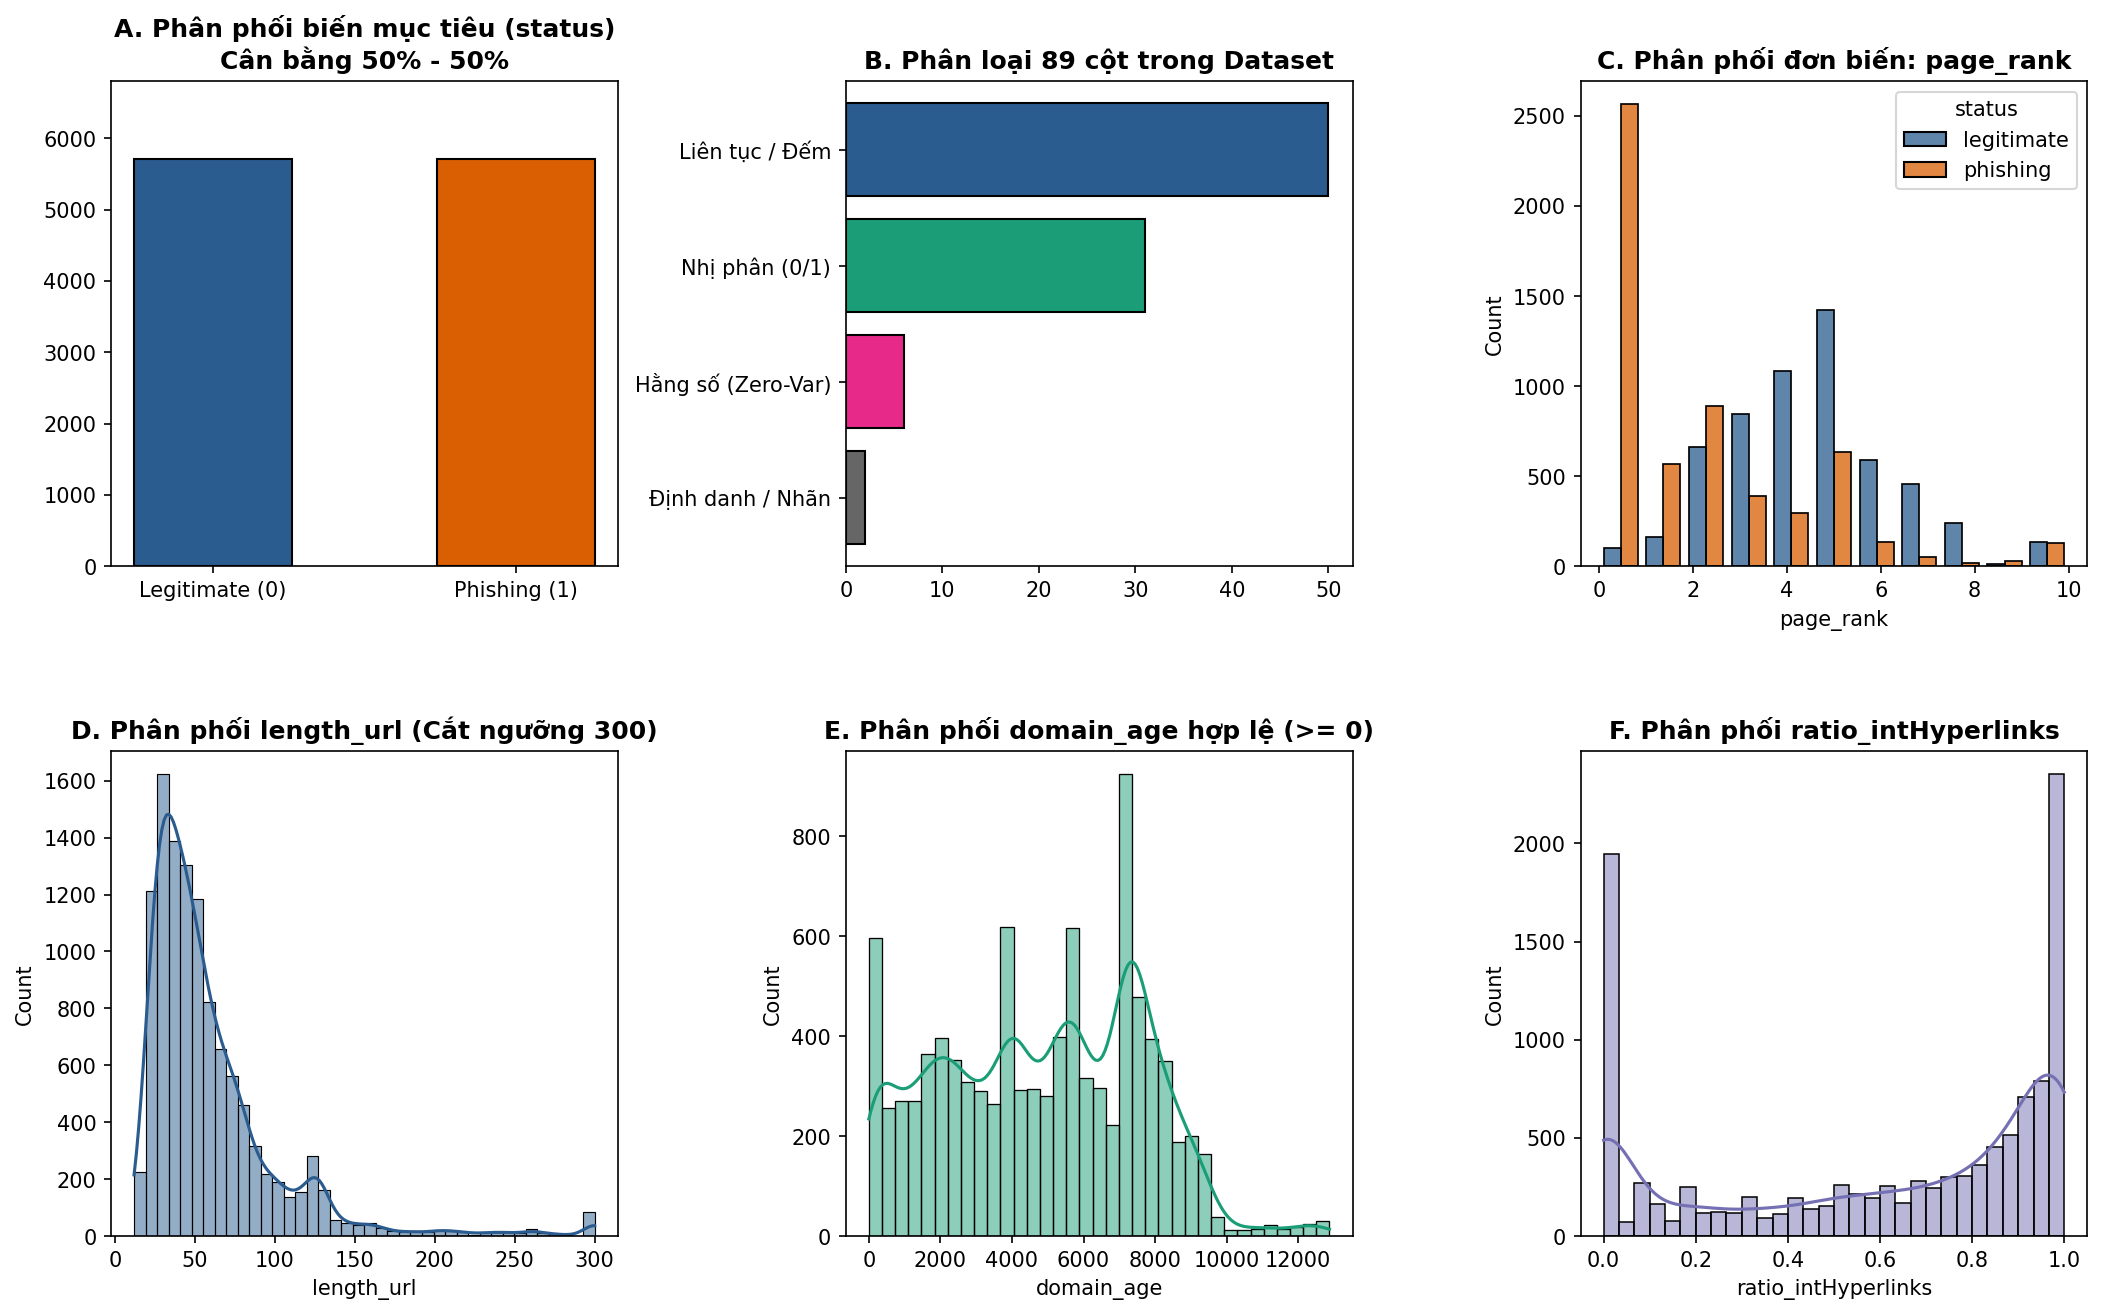

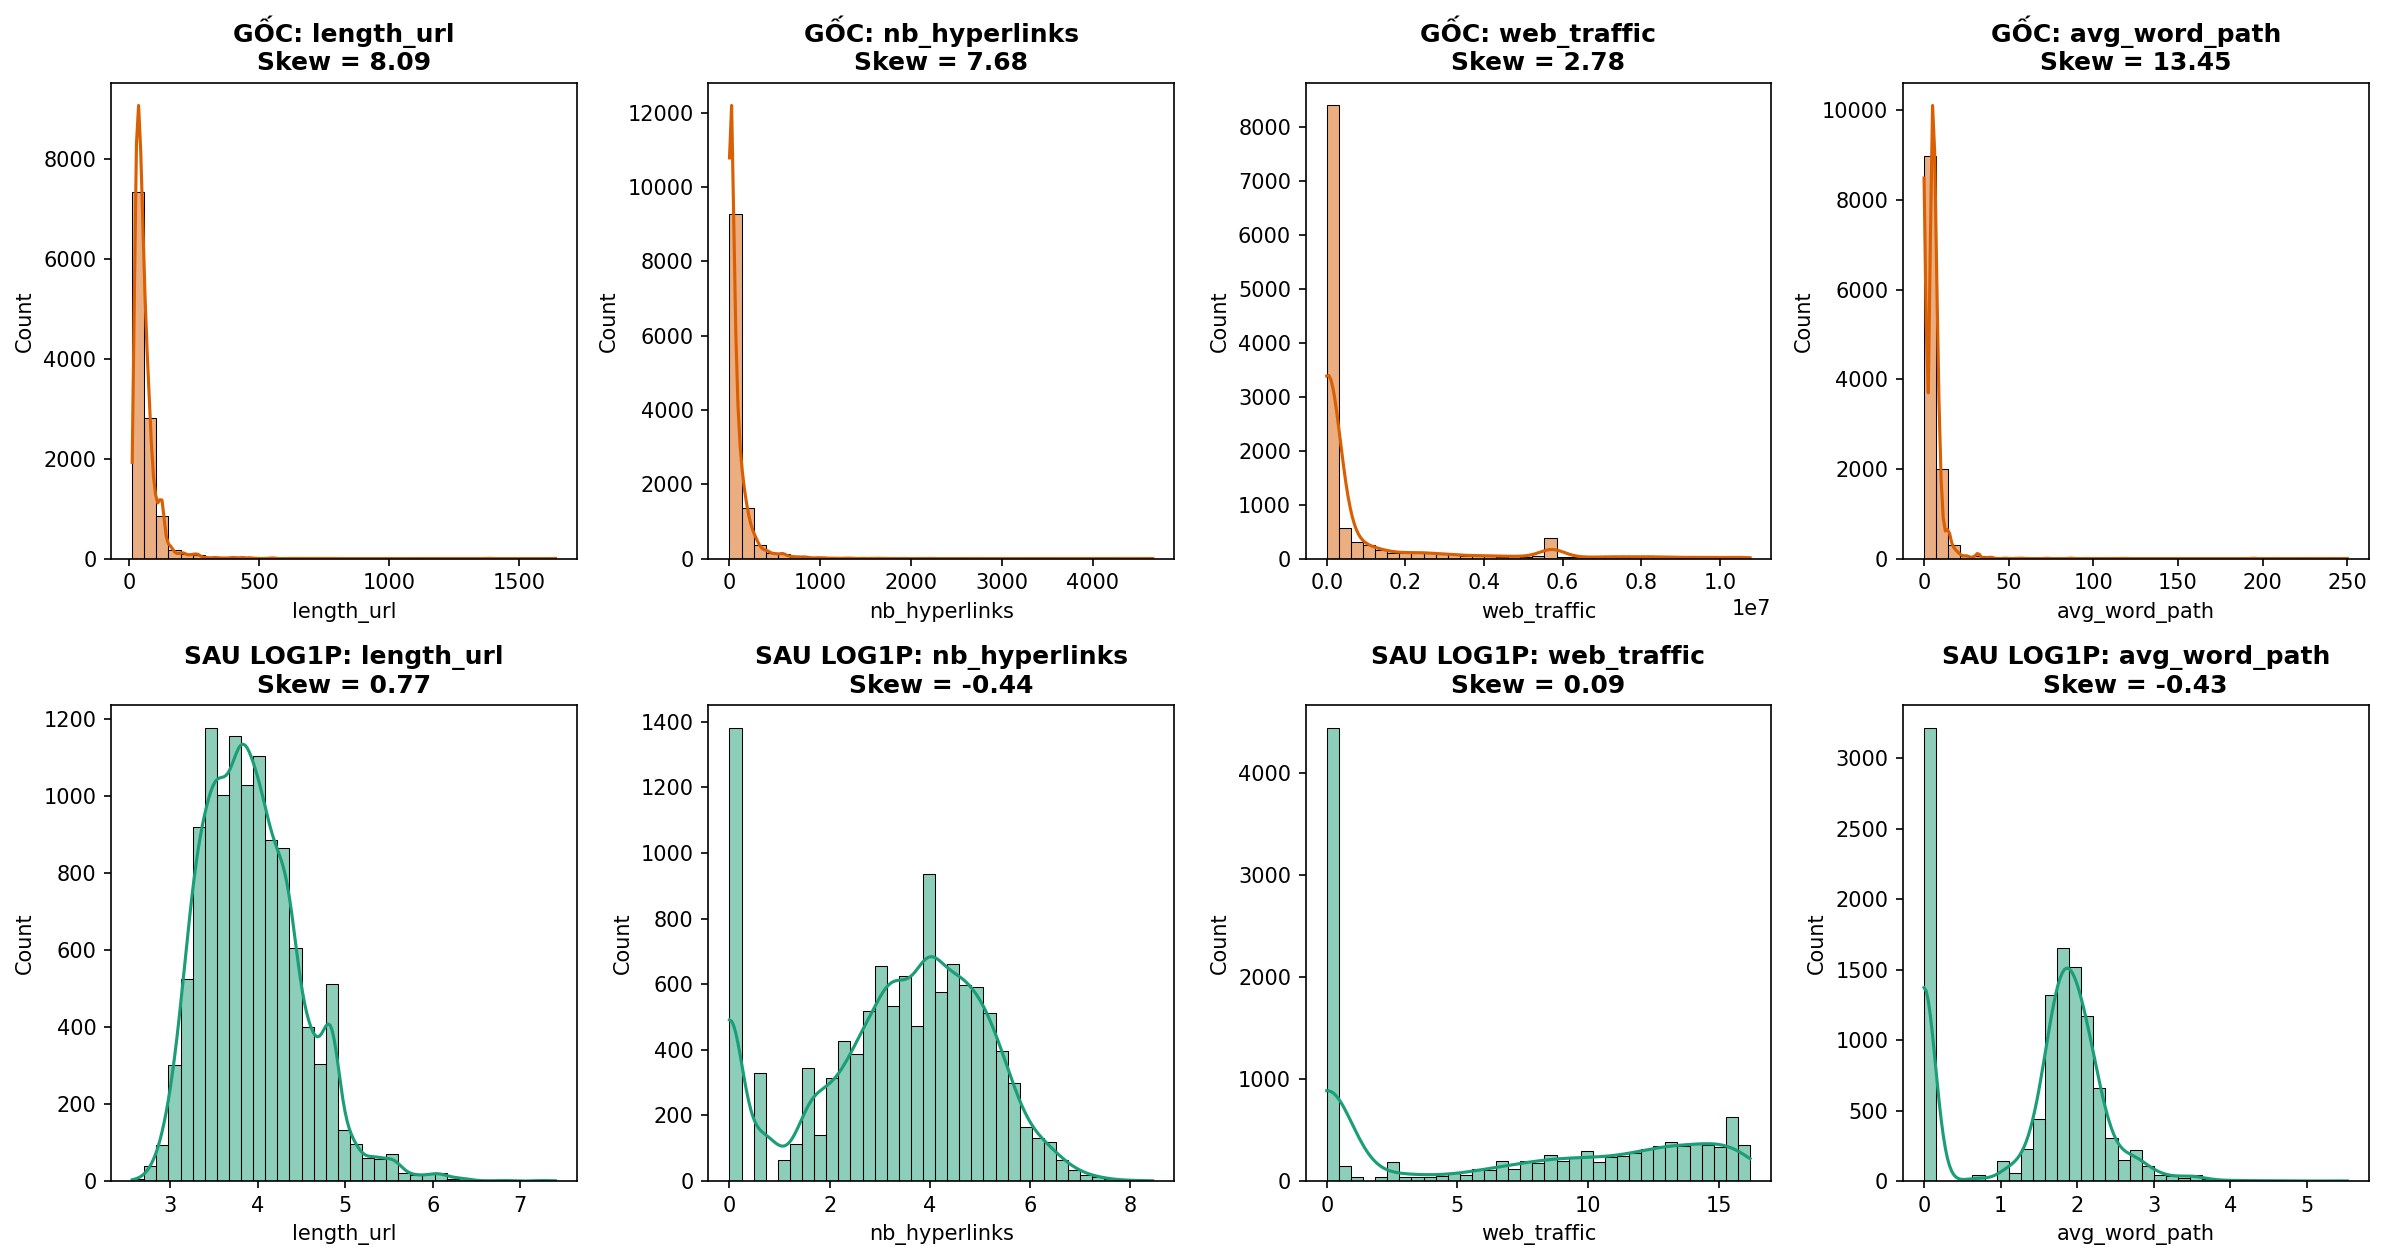

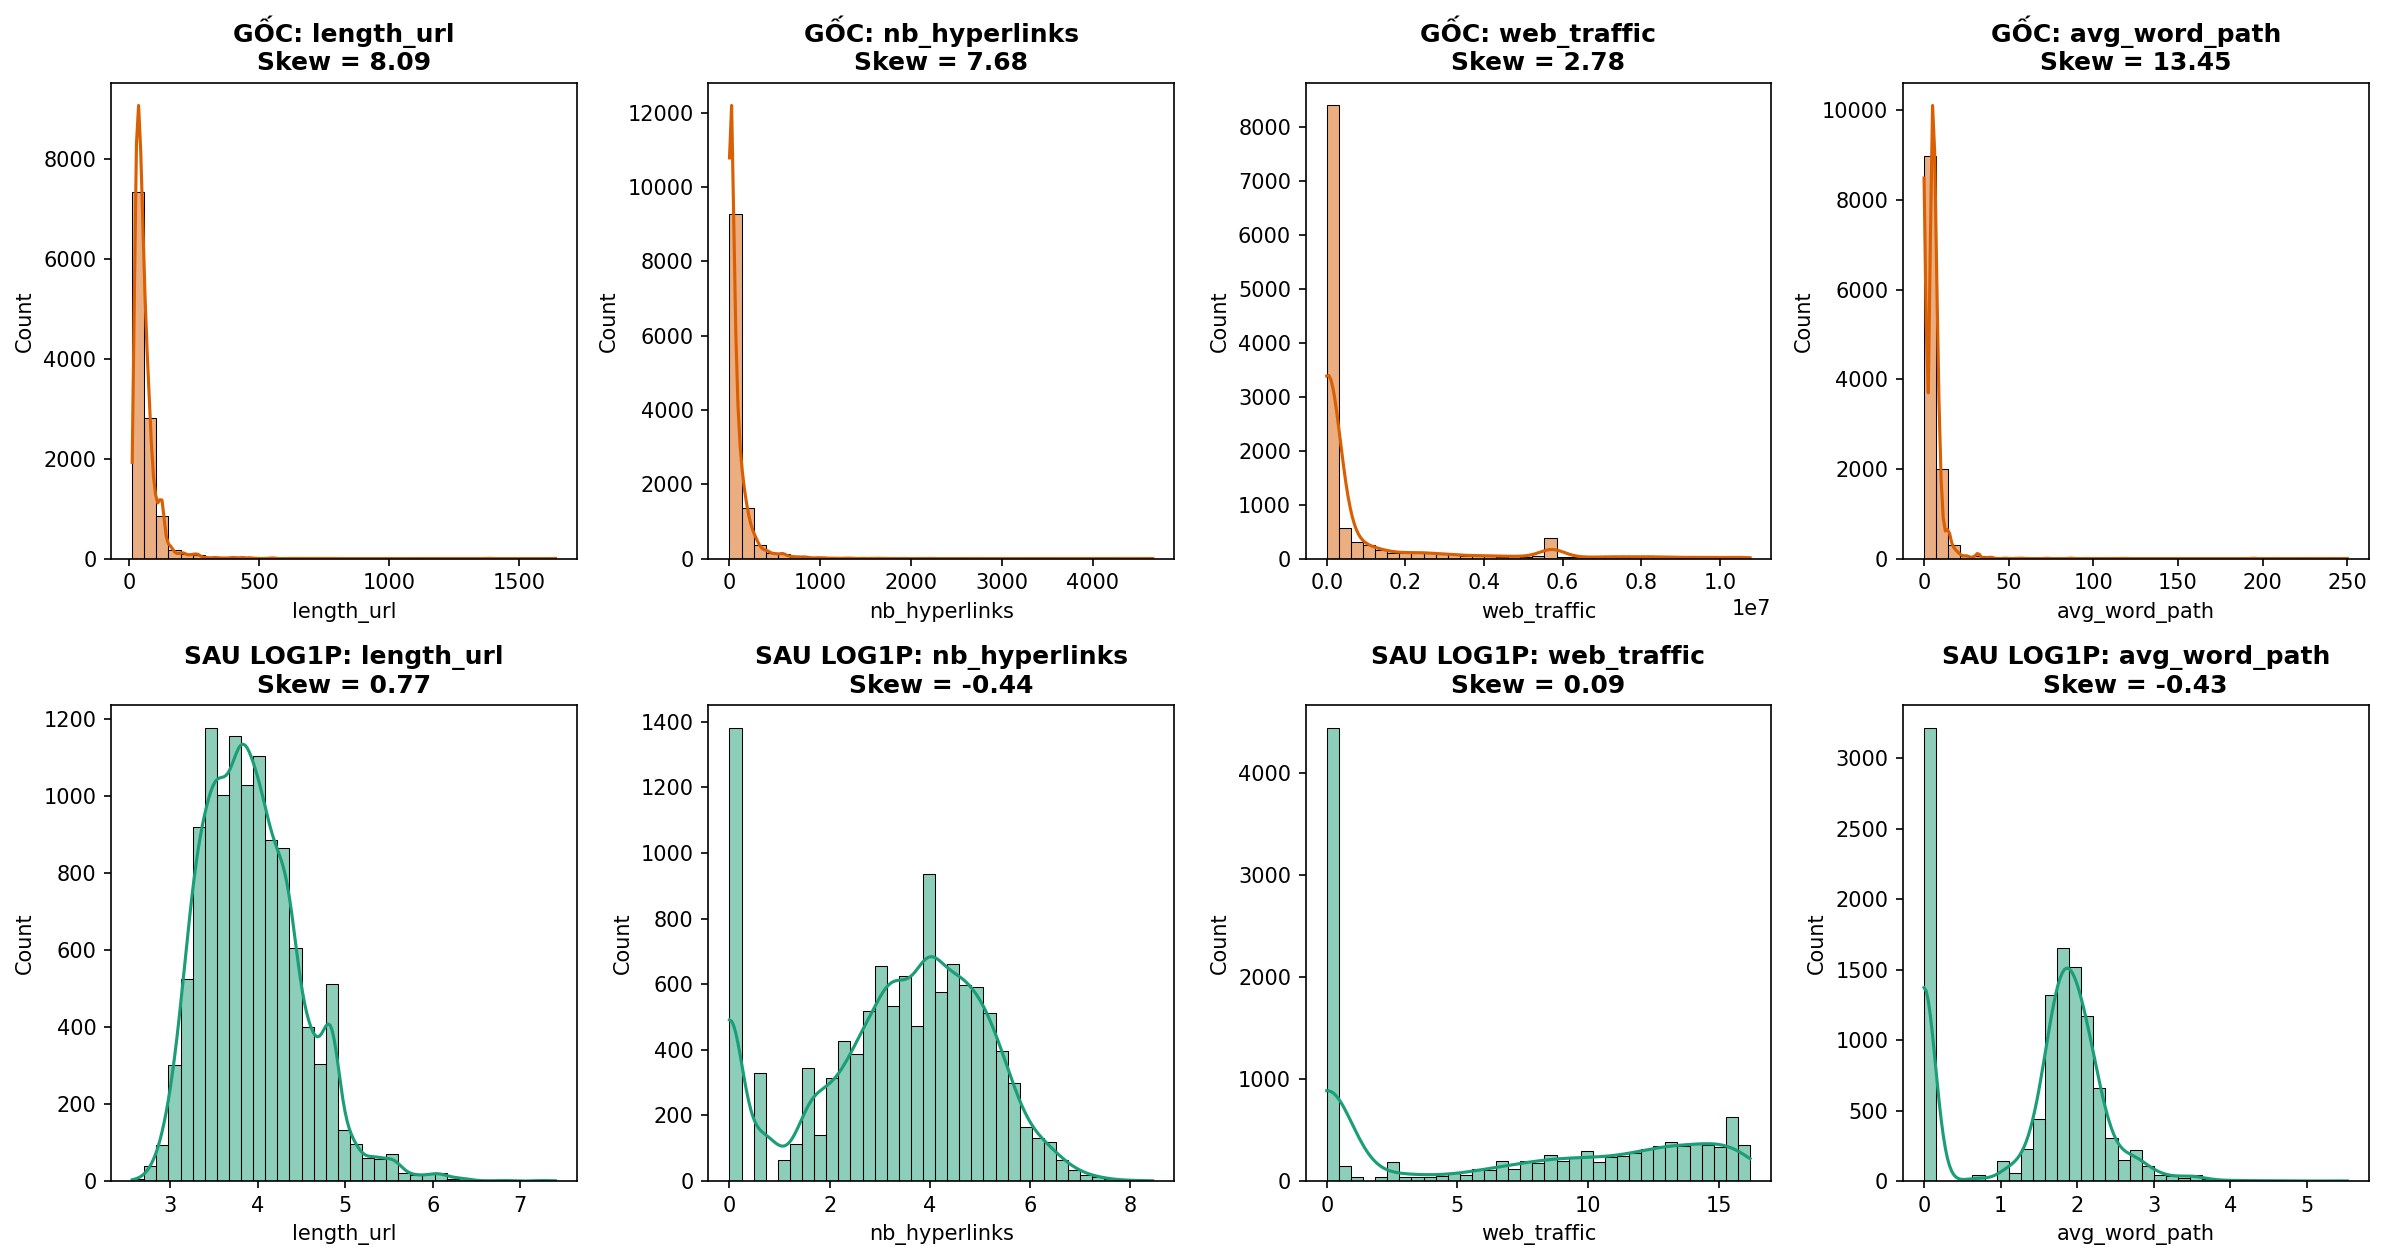

In [2]:
PALETTE = {'legitimate': '#2b5c8f', 'phishing': '#d95f02'}
COLOR_BLUE, COLOR_ORANGE, COLOR_TEAL, COLOR_PURPLE = '#2b5c8f', '#d95f02', '#1b9e77', '#7570b3'

# --- BIỂU ĐỒ 1: PHÂN TÍCH ĐƠN BIẾN (UNIVARIATE OVERVIEW) ---
fig = plt.figure(figsize=(17, 10), dpi=150)
gs = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.45)

ax1 = fig.add_subplot(gs[0, 0])
counts = df['status'].value_counts()
bars = ax1.bar(['Legitimate (0)', 'Phishing (1)'], [counts['legitimate'], counts['phishing']],
               color=[COLOR_BLUE, COLOR_ORANGE], width=0.52, edgecolor='black')
ax1.set_ylim(0, 6800)
ax1.set_title("A. Phân phối biến mục tiêu (status)\nCân bằng 50% - 50%", fontweight='bold')

ax2 = fig.add_subplot(gs[0, 1])
tax_labels = ['Liên tục / Đếm', 'Nhị phân (0/1)', 'Hằng số (Zero-Var)', 'Định danh / Nhãn']
tax_counts = [len(cont_cols), len(binary_cols), len(zero_var_cols), 2]
ax2.barh(tax_labels, tax_counts, color=[COLOR_BLUE, COLOR_TEAL, '#e7298a', '#666666'], edgecolor='black')
ax2.invert_yaxis()
ax2.set_title("B. Phân loại 89 cột trong Dataset", fontweight='bold')

ax3 = fig.add_subplot(gs[0, 2])
sns.histplot(data=df, x='page_rank', hue='status', multiple='dodge', bins=11, shrink=0.8, palette=PALETTE, ax=ax3)
ax3.set_title("C. Phân phối đơn biến: page_rank", fontweight='bold')

ax4 = fig.add_subplot(gs[1, 0])
sns.histplot(df['length_url'].clip(upper=300), bins=40, kde=True, color=COLOR_BLUE, ax=ax4)
ax4.set_title("D. Phân phối length_url (Cắt ngưỡng 300)", fontweight='bold')

ax5 = fig.add_subplot(gs[1, 1])
sns.histplot(df[df['domain_age'] >= 0]['domain_age'], bins=35, kde=True, color=COLOR_TEAL, ax=ax5)
ax5.set_title("E. Phân phối domain_age hợp lệ (>= 0)", fontweight='bold')

ax6 = fig.add_subplot(gs[1, 2])
sns.histplot(df['ratio_intHyperlinks'], bins=30, kde=True, color=COLOR_PURPLE, ax=ax6)
ax6.set_title("F. Phân phối ratio_intHyperlinks", fontweight='bold')

plt.savefig(f"{FIGURES_DIR}/eda_01_univariate_overview.png", bbox_inches='tight')
plt.show()

# --- BIỂU ĐỒ 2: HIỆU QUẢ BIẾN ĐỔI LOG1P TRÊN CÁC CỘT LỆCH PHẢI ---
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5), dpi=150)
demo_cols = ['length_url', 'nb_hyperlinks', 'web_traffic', 'avg_word_path']
for idx, col in enumerate(demo_cols):
    sns.histplot(df[col], bins=35, kde=True, color=COLOR_ORANGE, ax=axes[0, idx])
    axes[0, idx].set_title(f"GỐC: {col}\nSkew = {df[col].skew():.2f}", fontweight='bold')
    log_s = np.log1p(np.maximum(0, df[col]))
    sns.histplot(log_s, bins=35, kde=True, color=COLOR_TEAL, ax=axes[1, idx])
    axes[1, idx].set_title(f"SAU LOG1P: {col}\nSkew = {log_s.skew():.2f}", fontweight='bold')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/eda_03_skewness_and_transformation.png", bbox_inches='tight')
plt.show()


# --- BIỂU ĐỒ 2: HIỆU QUẢ BIẾN ĐỔI LOG1P TRÊN CÁC CỘT LỆCH PHẢI ---
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5), dpi=150)
demo_cols = ['length_url', 'nb_hyperlinks', 'web_traffic', 'avg_word_path']
for idx, col in enumerate(demo_cols):
    sns.histplot(df[col], bins=35, kde=True, color=COLOR_ORANGE, ax=axes[0, idx])
    axes[0, idx].set_title(f"GỐC: {col}\nSkew = {df[col].skew():.2f}", fontweight='bold')
    log_s = np.log1p(np.maximum(0, df[col]))
    sns.histplot(log_s, bins=35, kde=True, color=COLOR_TEAL, ax=axes[1, idx])
    axes[1, idx].set_title(f"SAU LOG1P: {col}\nSkew = {log_s.skew():.2f}", fontweight='bold')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/eda_03_skewness_and_transformation.png", bbox_inches='tight')
plt.show()
